# **Portfolio Forecast Demo: Quick Start with Daily Prices**

The shortest path from a price download to a forecast and a PDF report: a small portfolio of liquid stocks on daily closes, backtested, then forecast by all three simulators.

1. Download the last three years of daily prices for four stocks.
2. Backtest a buy-and-hold portfolio and read its performance report.
3. Forecast the portfolio with the three simulators.
4. Compare their fan charts.
5. Read the statistical reports.
6. Compile the results as a PDF (needs LaTeX).

The data window is relative to today, so every run uses fresh prices and the numbers in the outputs change from run to run.

## **Imports**

In [1]:
# The simulators, reports, fan charts and PDF builder, plus yfinance for the prices
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import yfinance as yf

from portfolio_forecast.forecast import nonparametric_monte_carlo, parametric_monte_carlo, regime_switching_monte_carlo
from portfolio_forecast.performance import performance_report, simulate_buy_and_hold, statistical_report
from portfolio_forecast.plotting import plot_path_comparison, plot_simulated_paths
from portfolio_forecast.reporting import compile_statistical_reports

## **Downloading Daily Prices**

`yf.download` returns every field (Close, High, Low, Open, Volume) for each ticker. `period='3y'` asks for the three years up to today, so nothing here is tied to a fixed date.

In [2]:
# Three years of daily bars for four liquid stocks, adjusted for splits and dividends
tickers = ['AAPL', 'MSFT', 'JPM', 'XOM']
data = yf.download(tickers, period='3y', interval='1d', auto_adjust=True, progress=False)
data['Close'].tail()

Ticker,AAPL,JPM,MSFT,XOM
Date,,,,
2026-10-05,332.890015,330.730011,525.179993,164.000000
2026-10-06,333.630005,331.279999,529.299988,164.479996
2026-10-07,336.670013,329.579987,529.760010,164.050003
2026-10-08,340.420013,331.420013,522.609985,168.500000
2026-10-09,336.640015,332.989990,535.070007,168.940002


## **Backtesting a Buy-and-Hold Portfolio**

`simulate_buy_and_hold` buys the portfolio at the first session's open and never rebalances it. It returns a `BacktestResult`: the value at the purchase and at every session close, each labelled with the moment it is true (the close, New York time), and the class of each return. A session still trading when the cell runs is left out, since its last price is not yet a close.

`performance_report` summarizes the history. Look at the total return against the max drawdown (how far the portfolio fell from a high on the way), and at the yearly returns table, whose first and last years are partial (`is_full` is `False`). Gap and Bar Volatility are intraday figures, so the report leaves them out on daily data (see [per-class volatility](../README.md#m5-per-class-volatility)).

In [3]:
# Fixed weights, normalized to sum to 1; the portfolio starts at $10,000
weights = {'AAPL': 0.30, 'MSFT': 0.30, 'JPM': 0.20, 'XOM': 0.20}
backtest = simulate_buy_and_hold(data, weights, br0=10_000)
history = performance_report(backtest, display=True)


            PORTFOLIO PERFORMANCE REPORT            
----------------------------------------------------
  Total Time         :  3.00 years (1095 days)
  Periods            :   753 returns
                      RETURNS                       
----------------------------------------------------
  Initial Bankroll   :     10000.00
  Final Bankroll     :     18950.15
  Total Return       :       89.50%
  CAGR               :       23.85%
----------------------------------------------------
  Actual Yearly Returns:
    - 2023            :        8.20%  (81 days)
    - 2024            :       24.76%  (full year)
    - 2025            :       19.01%  (full year)
    - 2026            :       17.95%  (280 days)
                        RISK                        
----------------------------------------------------
  Volatility         :       16.09%
  Downside Vol       :       10.79%
  Max Drawdown       :       20.14%
  Sharpe Ratio       :         1.42
  Sortino Ratio      :         2.1

## **Forecasting with the Three Simulators**

Each simulator takes the backtest as its history and returns a `SimulationResult`: the paths, the future sessions they run over and the fitted model. Every path starts at 1.0, the last backtested value, so 1.10 means the portfolio ended 10% higher. On daily history `sim_length` counts sessions; 63 is about three months. A thousand paths per method give stable ranges and still run in seconds.

- `nonparametric_monte_carlo` resamples the history's own daily returns.
- `parametric_monte_carlo` fits a normal, a Student's t and a Johnson SU distribution and uses the one with the lowest BIC; it prints each candidate's score.
- `regime_switching_monte_carlo` fits hidden Markov models with 1, 2 and 3 regimes and uses the lowest BIC; it prints each regime's mean, volatility and expected duration.

In [4]:
# The same horizon, path count and seed for every method, so only the model differs
horizon, n_paths = 63, 1000

sims_bootstrap = nonparametric_monte_carlo(backtest, sim_length=horizon, n_sims=n_paths,
                                           random_state=np.random.default_rng(42))

In [5]:
# distribution=None picks the family by BIC; the fit is in sims_parametric.fit['regular']
sims_parametric = parametric_monte_carlo(backtest, distribution=None, sim_length=horizon, n_sims=n_paths,
                                         random_state=np.random.default_rng(42))

      norm BIC: -4,771.07
         t BIC: -4,958.06


 johnsonsu BIC: -4,952.45
Selected: t  (df 3.7, loc 0.00119, scale 0.00668)


In [6]:
# n_regimes=None picks the regime count by BIC; the regimes, calmest first, are in sims_regime.fit
sims_regime = regime_switching_monte_carlo(backtest, n_regimes=None, sim_length=horizon, n_sims=n_paths,
                                           random_state=np.random.default_rng(42))
sims_regime.fit['Regimes']

1 regime(s) BIC: -4,771.07


2 regime(s) BIC: -4,935.77


3 regime(s) BIC: -4,928.99
Selected: 2 regime(s)
Regime 0: mean +0.1204%, vol 0.7444%, expected duration 28.6 marks
Regime 1: mean -0.3155%, vol 2.4658%, expected duration 2.5 marks


,Mean,Volatility,Expected Duration,Current Probability
Regime,,,,
0,0.001204,0.007444,28.621505,0.985817
1,-0.003155,0.024658,2.545178,0.014183


## **Comparing the Fan Charts**

`plot_simulated_paths` draws one method's paths, colored by where each ends, with the median path in red and the starting value dashed. The x-axis reads the future sessions from the result, so no dates are passed.

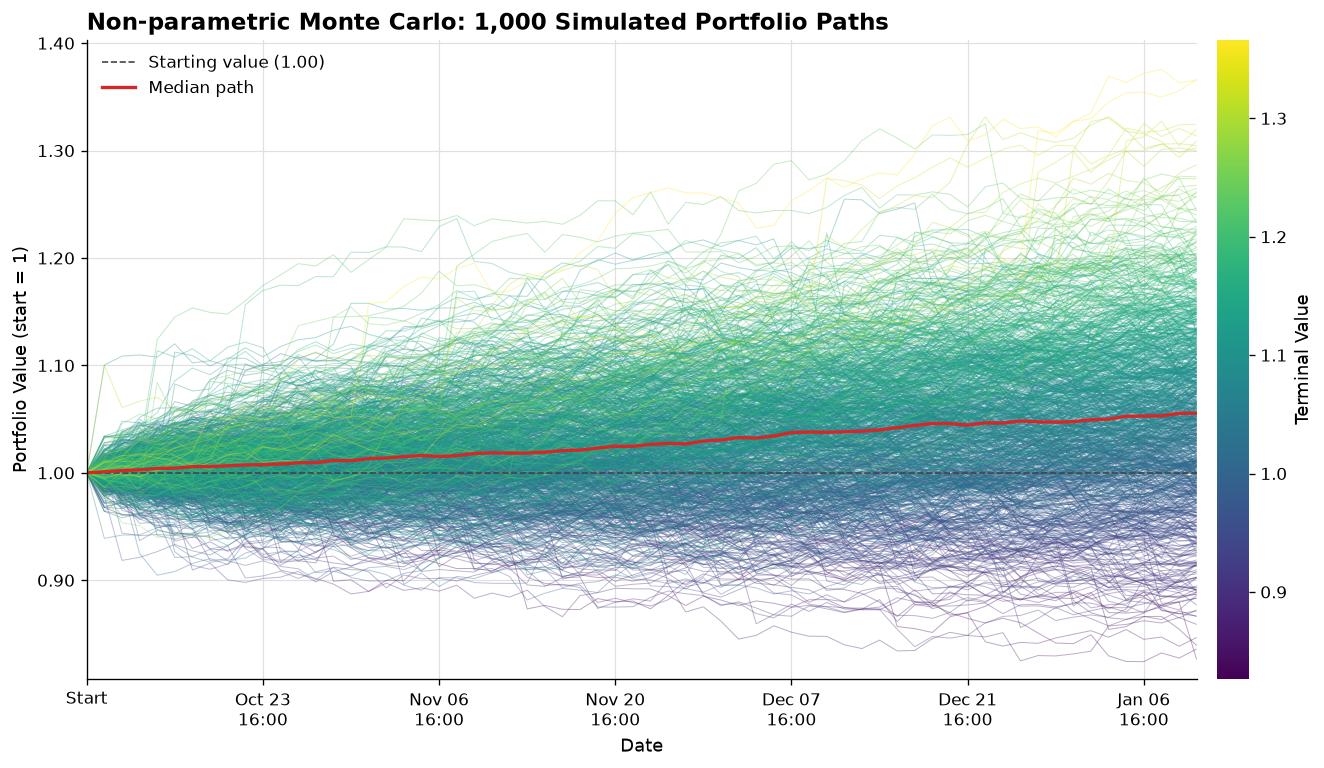

In [7]:
# One method's fan chart
fig, ax = plot_simulated_paths(sims_bootstrap, method='Non-parametric Monte Carlo')
plt.show()

`plot_path_comparison` puts the methods side by side on a shared y-axis and one color scale, so the spread of each fan compares directly. Look at how wide each fan is at the right edge, and whether one method puts more paths in the tails than the others.

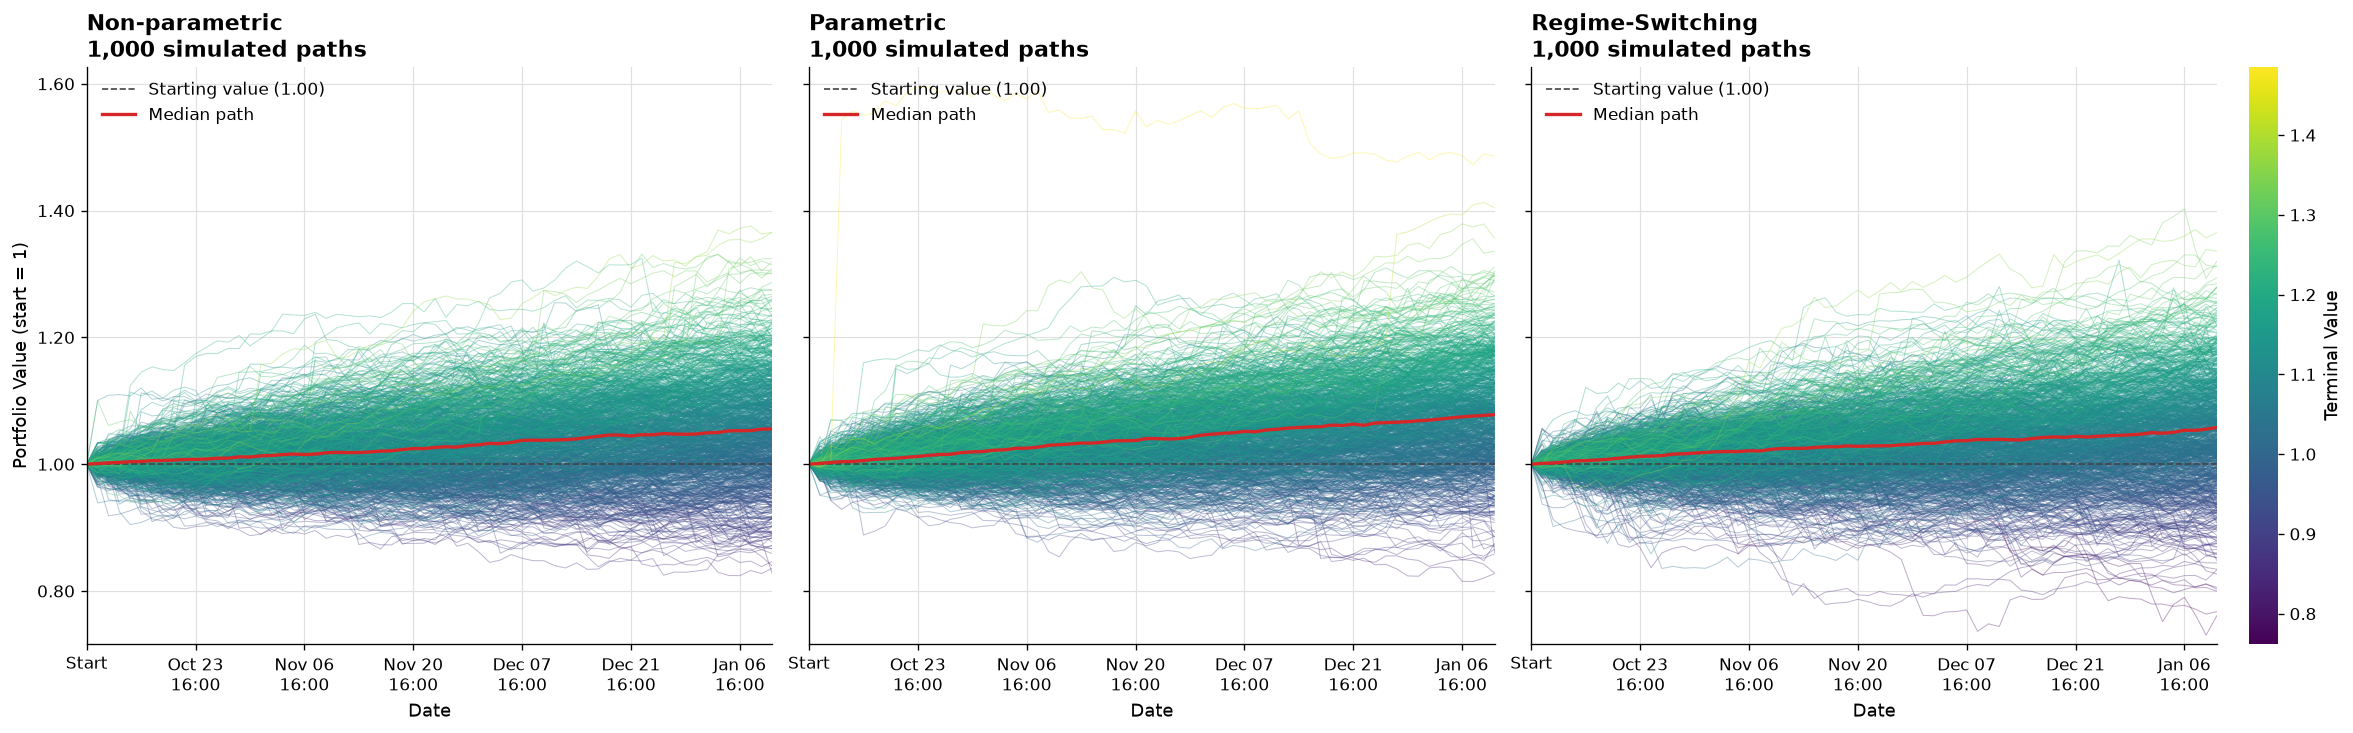

In [8]:
# All three methods side by side, on a shared y-axis and color scale
methods = {
    'Non-parametric': sims_bootstrap,
    'Parametric': sims_parametric,
    'Regime-Switching': sims_regime,
}
fig_comparison, axes = plot_path_comparison(methods)
plt.show()

## **Reading the Statistical Reports**

`statistical_report` computes every figure of the performance report on each path, then summarizes it by its mean, median and range across paths. Lower and Upper bound the central 95% of paths under the fitted model: a spread of outcomes, not a confidence interval. Compare the methods' Total Return ranges and their tail risk: the probability of loss, and the value at risk and conditional VaR at the 5% tail. Over a few months CAGR annualizes a short horizon and reads much larger than the total return; the total return is the figure to read here.

On a short horizon some paths never have a down session, so their Sortino ratio is infinite; the report warns with the count when that happens.

In [9]:
# Each method's report, printed, and kept for the PDF
reports = {}
for method, sims in methods.items():
    print(f'{method} Monte Carlo')
    reports[method] = statistical_report(sims, display=True)

Non-parametric Monte Carlo



                     SIMULATED PORTFOLIO STATISTICAL REPORT                     
--------------------------------------------------------------------------------
  Simulated Paths      : 1,000
  Total Time           :  0.26 years (94 days)
  Horizon              :    63 periods
                                    RETURNS                                     
--------------------------------------------------------------------------------
                               Mean       Median         95% range across paths
--------------------------------------------------------------------------------
  Final Bankroll       :       1.06         1.06                   [0.90, 1.23]
  Total Return         :      5.96%        5.55%               [-9.80%, 23.31%]
  CAGR                 :     30.97%       24.13%             [-33.81%, 131.19%]
                                      RISK                                      
----------------------------------------------------------------------------


                     SIMULATED PORTFOLIO STATISTICAL REPORT                     
--------------------------------------------------------------------------------
  Simulated Paths      : 1,000
  Total Time           :  0.26 years (94 days)
  Horizon              :    63 periods
                                    RETURNS                                     
--------------------------------------------------------------------------------
                               Mean       Median         95% range across paths
--------------------------------------------------------------------------------
  Final Bankroll       :       1.08         1.08                   [0.93, 1.25]
  Total Return         :      8.07%        7.82%               [-7.27%, 24.89%]
  CAGR                 :     41.43%       35.14%             [-26.06%, 143.29%]
                                      RISK                                      
----------------------------------------------------------------------------


                     SIMULATED PORTFOLIO STATISTICAL REPORT                     
--------------------------------------------------------------------------------
  Simulated Paths      : 1,000
  Total Time           :  0.26 years (94 days)
  Horizon              :    63 periods
                                    RETURNS                                     
--------------------------------------------------------------------------------
                               Mean       Median         95% range across paths
--------------------------------------------------------------------------------
  Final Bankroll       :       1.06         1.06                   [0.88, 1.23]
  Total Return         :      5.66%        5.78%              [-11.63%, 23.43%]
  CAGR                 :     29.80%       25.22%             [-39.00%, 132.09%]
                                      RISK                                      
----------------------------------------------------------------------------

## **PDF Report**

`compile_statistical_reports` typesets the reports and figures with LaTeX and needs `pdflatex` on the PATH. It takes a dictionary with a title, an introduction and one entry per report, each with a description, the results of `statistical_report` and its figures. The PDF is saved to `Reporting/` in the working directory (here, the `demos` folder), and no other files are left behind. Text is printed literally, so `%` and `&` need no escaping.

In [10]:
# One fan chart per method for the PDF; closed here so they are not drawn twice
figures = {method: plot_simulated_paths(sims, method=f'{method} Monte Carlo')[0] for method, sims in methods.items()}
plt.close('all')

descriptions = {
    'Non-parametric': 'Resamples the daily returns of the backtest with replacement.',
    'Parametric': 'Draws daily log returns from the distribution with the lowest BIC.',
    'Regime-Switching': 'Moves between fitted volatility regimes, so turbulent sessions cluster.',
}
start, end = backtest.dates[0], backtest.dates[-1]
report_spec = {
    'Title': f'Four-Stock Portfolio: {horizon}-Session Outlook',
    'Introduction': (f"A buy-and-hold portfolio of {', '.join(tickers)}, backtested on daily prices from "
                     f"{start:%d %B %Y} to {end:%d %B %Y} and forecast {horizon} sessions ahead with "
                     f"{n_paths} paths per method."),
    'Reports': {
        f'{method} Monte Carlo': {
            'Description': descriptions[method],
            'Results': reports[method],
            'Figures': {'Paths': {'Image': figures[method], 'Caption': 'Simulated paths and their median.',
                                  'Width': 0.85}},
        }
        for method in methods
    },
}
# The comparison chart goes in the last report, at full width
report_spec['Reports']['Regime-Switching Monte Carlo']['Figures']['Comparison'] = {
    'Image': fig_comparison, 'Caption': 'The three methods on a shared y-axis and color scale.'}

In [11]:
# Typeset the PDF if pdflatex is installed; otherwise say what is missing
if shutil.which('pdflatex') is None:
    print('pdflatex is not on the PATH, so the PDF is skipped; install a LaTeX distribution to build it.')
else:
    pdf = compile_statistical_reports(report_spec)
    print(f'Saved {pdf.relative_to(Path.cwd())}')

Saved Reporting/Four_Stock_Portfolio_63_Session_Outlook.pdf
